In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

%matplotlib inline

In [58]:
df_bc=pd.read_csv("data.csv")

In [59]:
df_bc

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [60]:
print(df_bc.shape)
print(df_bc.head())
print('data types: ',df_bc.dtypes.value_counts())
print(df_bc['diagnosis'].value_counts())

(569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  

In [61]:
print('missing values: ',df_bc.isnull().sum())
print('duplicates: ',df_bc.duplicated().sum())




missing values:  id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_wors

In [62]:

x = df_bc.drop(columns=['id', 'diagnosis', 'Unnamed: 32'])
y = (df_bc['diagnosis'] == 'M').astype(int)   # M = 1 (malignant), B = 0 (benign)

print(x.shape)          
print(y.value_counts())

(569, 30)
diagnosis
0    357
1    212
Name: count, dtype: int64


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, stratify=y, random_state=42)

In [64]:
scaler = StandardScaler().fit(X_train)
feature_names = list(x.columns)

X_train = scaler.transform(X_train)   # numpy arrays from now on: columns are picked by index

X_test  = scaler.transform(X_test)
y_train, y_test = y_train.to_numpy(),y_test.to_numpy()

n_features = X_train.shape[1]         # 30
print(X_train.shape, X_test.shape)   # (455, 30) (114, 30)
print(n_features, X_train.mean().round(3), X_train.std().round(3))


(455, 30) (114, 30)
30 0.0 1.0


In [65]:

from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

def make_fitness(X_train, y_train, lam=0.1, k_neighbors=5):
    n = X_train.shape[1]

    def error_rate(s):
        cols = np.where(s == 1)[0]
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        return 1 - cross_val_score(model, X_train[:, cols], y_train, cv=5).mean()

    def fitness(s):
        if s.sum() == 0:
            return np.inf
        return error_rate(s) + lam * s.sum() / n

    return fitness, error_rate

fitness, error_rate = make_fitness(X_train, y_train, lam=0.1, k_neighbors=5)

In [66]:
# ---- 7. Swap neighborhood: 
def neighbors(s):
    for i in range(len(s)):
        s_new = s.copy()
        s_new[i] = 1 - s_new[i]
        yield s_new, i

In [67]:
# ---- 9. Tabu search (flip version) ----
def tabu_search(fitness, s_init, tenure=5, max_iter=30):
    n = len(s_init)
    s = s_init.copy()
    f_s = fitness(s)
    best_s, best_f = s.copy(), f_s

    tabu_until = np.zeros(n, dtype=int)
    history, best_history = [f_s], [best_f]
    feature_count_history, move_history = [int(s.sum())], []

    for it in range(1, max_iter + 1):
        chosen, chosen_f, chosen_move = None, np.inf, None

        for s_new, i in neighbors(s):                 # CHANGE 1: one index only
            f_new = fitness(s_new)
            is_tabu = tabu_until[i] >= it             # CHANGE 2: only i
            aspiration = f_new < best_f
            if is_tabu and not aspiration:
                continue
            if f_new < chosen_f:
                chosen, chosen_f, chosen_move = s_new, f_new, i

        if chosen is None:
            break

        s, f_s = chosen, chosen_f
        i = chosen_move
        tabu_until[i] = it + tenure                   # freeze only feature i

        if f_s < best_f:
            best_s, best_f = s.copy(), f_s

        history.append(f_s)
        best_history.append(best_f)
        feature_count_history.append(int(s.sum()))
        action = "add" if s[i] == 1 else "remove"
        move_history.append((i, action))     # CHANGE 3: new print line
        print(f"it {it:2d} | {action:<6s} {feature_names[i]:<24s} | f={f_s:.4f} | best={best_f:.4f} | k={s.sum()}")

    return best_s, best_f, history, best_history, feature_count_history, move_history


In [68]:
s0 = rng.integers(0, 2, size=X_train.shape[1])
s0

array([0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 1, 0, 1, 1])

it  1 | add    texture_worst            | f=0.0785 | best=0.0785 | k=13
it  2 | remove perimeter_mean           | f=0.0708 | best=0.0708 | k=12
it  3 | remove symmetry_mean            | f=0.0696 | best=0.0696 | k=11
it  4 | remove perimeter_worst          | f=0.0641 | best=0.0641 | k=10
it  5 | remove fractal_dimension_worst  | f=0.0608 | best=0.0608 | k=9
it  6 | remove texture_se               | f=0.0574 | best=0.0574 | k=8
it  7 | remove area_se                  | f=0.0541 | best=0.0541 | k=7
it  8 | remove radius_worst             | f=0.0530 | best=0.0530 | k=6
it  9 | remove symmetry_se              | f=0.0496 | best=0.0496 | k=5
it 10 | add    concave points_mean      | f=0.0486 | best=0.0486 | k=6
it 11 | remove compactness_mean         | f=0.0452 | best=0.0452 | k=5
it 12 | remove compactness_worst        | f=0.0375 | best=0.0375 | k=4
it 13 | remove compactness_se           | f=0.0386 | best=0.0375 | k=3
it 14 | add    concavity_se             | f=0.0375 | best=0.0375 | k=4
it

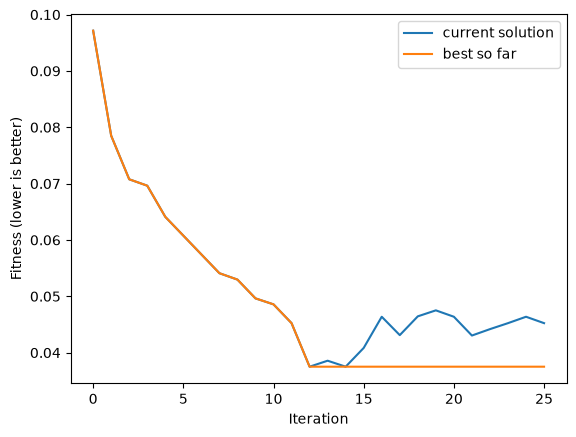

In [69]:
# Reproducible initial solution
rng = np.random.default_rng(42)
s0 = rng.integers(0, 2, size=X_train.shape[1])
s0=np.array([0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,1,0,0,1,0,1,0,1,1,0,1,0,0,0,1])
best_s, best_f, hist, best_hist, feature_count_history, move_history = tabu_search(fitness, s0, tenure=5, max_iter=25)

print("Best fitness:", round(best_f, 4), "| selected features:", int(best_s.sum()))
print([feature_names[i] for i in np.where(best_s == 1)[0]])

plt.plot(hist, label="current solution")
plt.plot(best_hist, label="best so far")
plt.xlabel("Iteration")
plt.ylabel("Fitness (lower is better)")
plt.legend()
plt.show()


tabu algo stats


In [70]:

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Selected features
selected_idx = np.flatnonzero(best_s)

if len(selected_idx) == 0:
    raise ValueError("No features selected.")

# Train model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

model.fit(X_train[:, selected_idx], y_train)

# Evaluate on test set
pred = model.predict(X_test[:, selected_idx])

# Collect essential statistics
tabu_stats = {
    "Algorithm": "Tabu Search",
    "Features": len(selected_idx),
    "CV Error": error_rate(best_s),
    "Test Accuracy": accuracy_score(y_test, pred),
    "Test F1": f1_score(y_test, pred)
}

print(pd.DataFrame([tabu_stats]))
print("Selected features:", selected_idx)


     Algorithm  Features  CV Error  Test Accuracy  Test F1
0  Tabu Search         4  0.024176       0.964912  0.95122
Selected features: [ 7 15 21 23]


In [71]:
spam = fetch_ucirepo(id=94)
X_spam = spam.data.features
y_spam = spam.data.targets.squeeze()

df_spam = pd.concat([X_spam, y_spam.rename("target")], axis=1)


KeyboardInterrupt: 

In [ ]:
df_spam

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,target
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.000,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.010,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4596,0.31,0.00,0.62,0.0,0.00,0.31,0.00,0.00,0.00,0.00,...,0.000,0.232,0.0,0.000,0.000,0.000,1.142,3,88,0
4597,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.353,0.000,0.000,1.555,4,14,0
4598,0.30,0.00,0.30,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.102,0.718,0.0,0.000,0.000,0.000,1.404,6,118,0
4599,0.96,0.00,0.00,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.057,0.0,0.000,0.000,0.000,1.147,5,78,0


In [72]:

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

scores = cross_val_score(
    model,
    X_train[:, selected_idx],
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("CV Accuracy:", scores.mean())


CV Accuracy: 0.9714285714285713


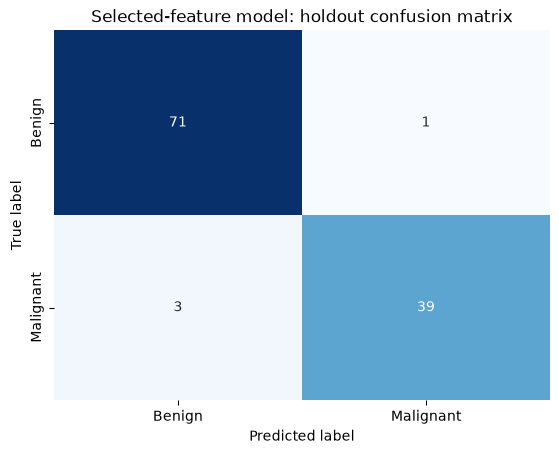

In [77]:
# Confusion matrix heatmap for the selected model.
cm = confusion_matrix(y_test, pred, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Selected-feature model: holdout confusion matrix")
plt.show()


### Tabu search result plots
These plots summarize the search trajectory and compare the final selected-feature model with an all-feature logistic-regression baseline. The saved `stats` table and these evaluation definitions can be reused for other feature-selection algorithms on the same fixed split.

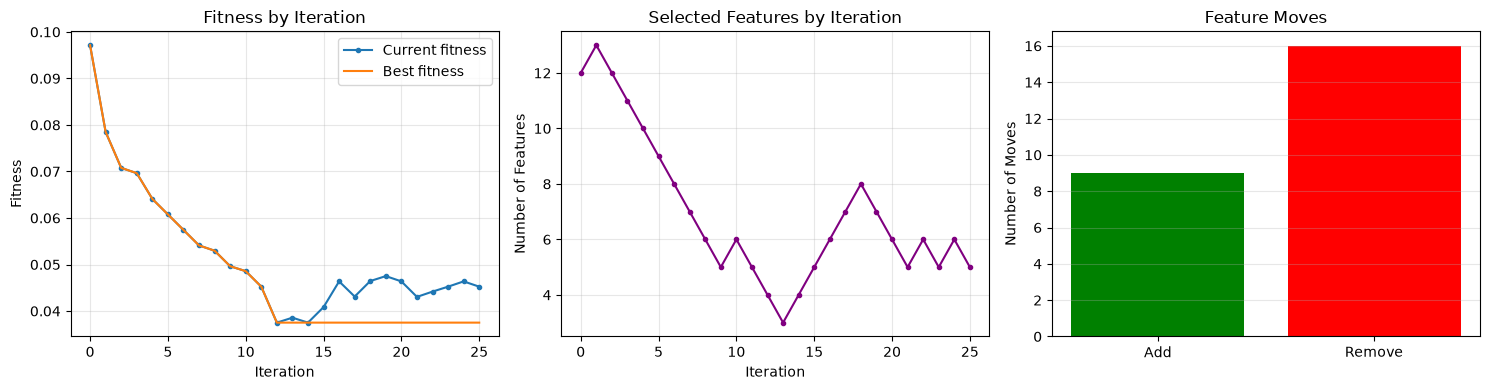

In [81]:

# ---- Tabu Search Statistics ----

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Fitness by iteration
axes[0].plot(hist, label="Current fitness", marker="o", ms=3)
axes[0].plot(best_hist, label="Best fitness")
axes[0].set_title("Fitness by Iteration")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Fitness")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Number of selected features
axes[1].plot(feature_count_history, color="purple", marker="o", ms=3)
axes[1].set_title("Selected Features by Iteration")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Number of Features")
axes[1].grid(alpha=0.3)

# 3. Feature moves
moves = pd.Series([action for _, action in move_history]).value_counts()

axes[2].bar(
    ["Add", "Remove"],
    [moves.get("add", 0), moves.get("remove", 0)],
    color=["green", "red"]
)
axes[2].set_title("Feature Moves")
axes[2].set_ylabel("Number of Moves")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
